# 05 Using a drive cycle

PyBaMM provides a number of example drive cycles that define the instantaneous current which can be read in from csv files. So we first change our current directory to the PyBaMM root directory in order to read it in.

In [1]:
%pip install "pybamm<=23.9" "numpy<2.0,>=1.26.4" "pandas<2.0" liionpack matplotlib

# MAKE SURE YOU ARE ON PYTHON 3.11 NO NEWER

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
import liionpack as lp

# Enable inline plotting for Jupyter
%matplotlib inline

In [4]:
# import drive cycle from file
drive_cycle = pd.read_csv("../../../../../../../workspaces/liionpacktesting/data/ioniq.csv", comment="#"
).to_numpy()

Let's have a look at the drive cycle. The first column is the time stamp and the second is the current.

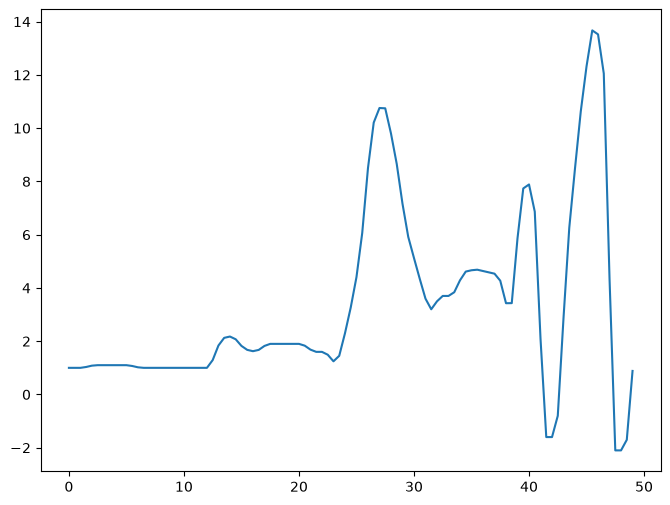

In [5]:
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'white'  # Use 'none' for transparent
    plt.rcParams['axes.facecolor'] = 'white'    # Use 'none' for transparent
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'    # Forces axis border/lines to be visible
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(drive_cycle[:, 0], drive_cycle[:, 1])
    
    # Force all axis spines to be visible and black
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)
        
    plt.show()

We can load an experiment using the drive cycle and give it a dictionary key and an operating condition to run it. N.B this is a new feature for PyBaMM and syntax may change so please consult the documentation and make sure you have the latest version of PyBaMM.

In [25]:
experiment = pybamm.Experiment(
    [pybamm.step.current(drive_cycle)],
    period="0.5 second",
)

Set up our pack using our chemistry of interest.

In [20]:
netlist = lp.setup_circuit(Np=2, Ns=192, Rb=1e-4, Rc=1e-3, Ri=5e-2, V=4.0, I=14.0)

In [21]:
# Heat transfer coefficients
htc = np.ones(4) * 10
# PyBaMM parameters
parameter_values = pybamm.ParameterValues("Chen2020")

In [ ]:
def custom_sim_func(parameter_values):
    # 1. Create a fresh DFN instance inside the function
    model = pybamm.lithium_ion.SPMe()
    
    # 2. Add liionpack event cutoffs (CRITICAL to avoid CasADi matrix errors)
    model = lp.add_events_to_model(model)
    
    # 3. Return the PyBaMM Simulation
    return pybamm.Simulation(
        model,
        parameter_values=parameter_values,
        experiment=experiment,
    )

In [37]:
print(model.variable_names())

['Time [s]', 'Time [min]', 'Time [h]', 'x [m]', 'x_n [m]', 'x_s [m]', 'x_p [m]', 'r_n [m]', 'r_p [m]', 'Current variable [A]', 'Total current density [A.m-2]', 'Current [A]', 'C-rate', 'Discharge capacity [A.h]', 'Throughput capacity [A.h]', 'Discharge energy [W.h]', 'Throughput energy [W.h]', 'Porosity', 'Negative electrode porosity', 'X-averaged negative electrode porosity', 'Separator porosity', 'X-averaged separator porosity', 'Positive electrode porosity', 'X-averaged positive electrode porosity', 'Porosity change', 'Negative electrode porosity change [s-1]', 'X-averaged negative electrode porosity change [s-1]', 'Separator porosity change [s-1]', 'X-averaged separator porosity change [s-1]', 'Positive electrode porosity change [s-1]', 'X-averaged positive electrode porosity change [s-1]', 'Negative electrode interface utilisation variable', 'X-averaged negative electrode interface utilisation variable', 'Negative electrode interface utilisation', 'X-averaged negative electrode in

In [34]:
# Solve pack
output_d = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=experiment,
    initial_soc=0.965,
    sim_func=custom_sim_func,
)

Stepping simulation: 100%|██████████| 99/99 [00:29<00:00,  3.33it/s]


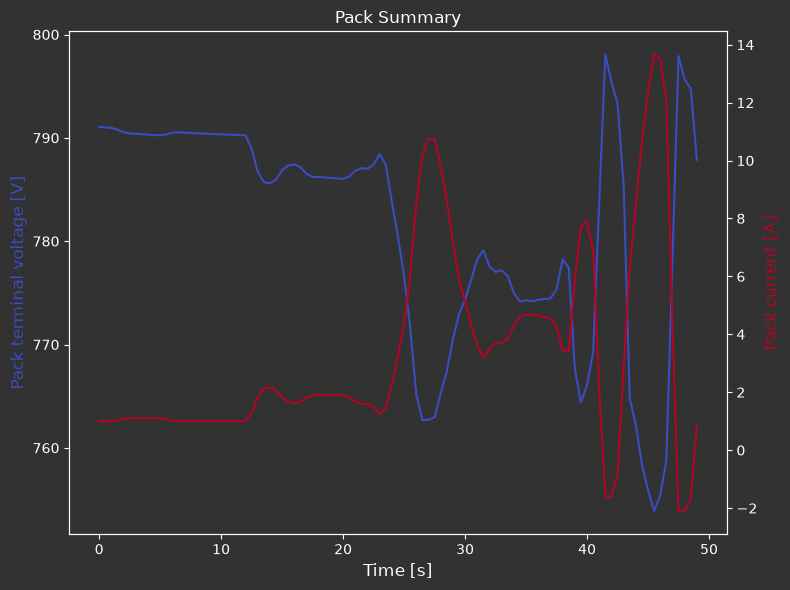

In [35]:
lp.plot_pack(output_d)
lp.show_plots()

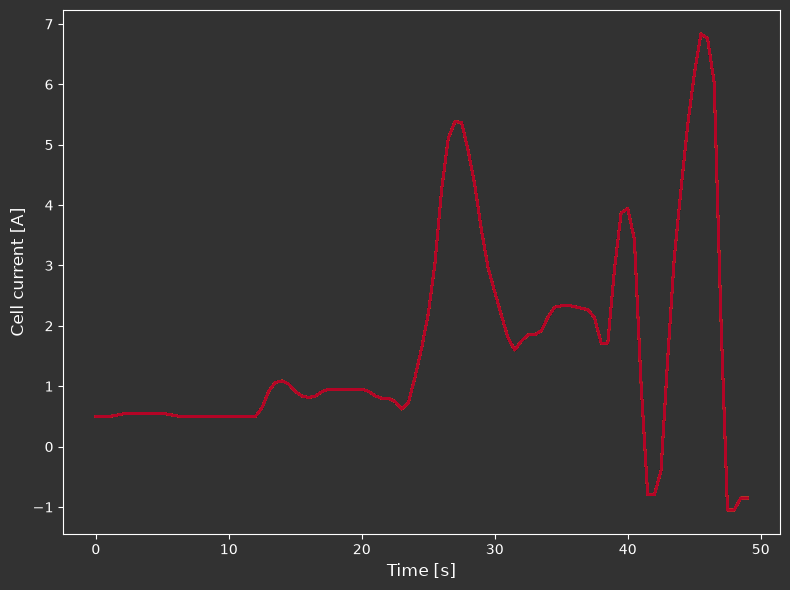

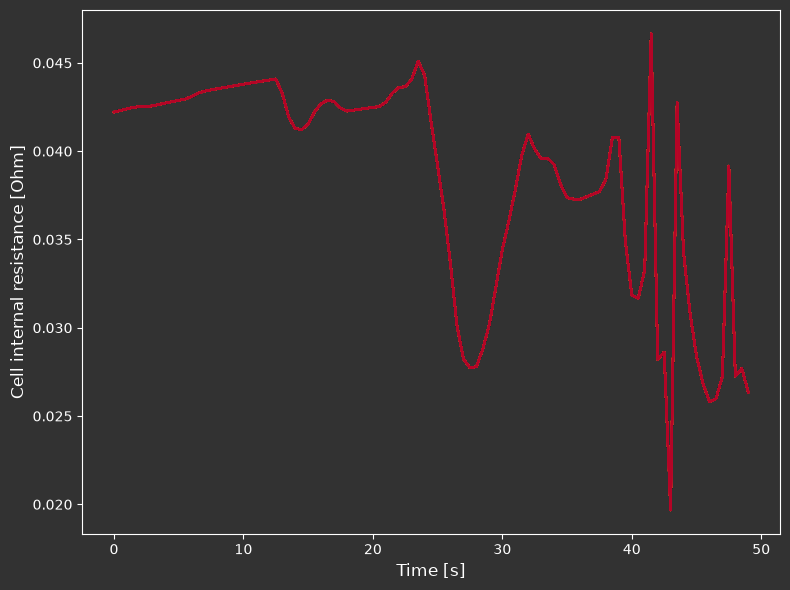

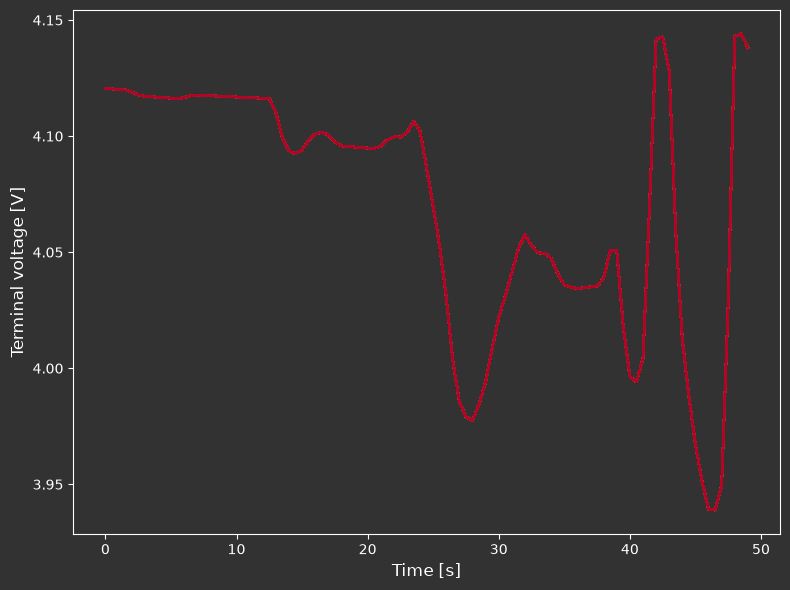

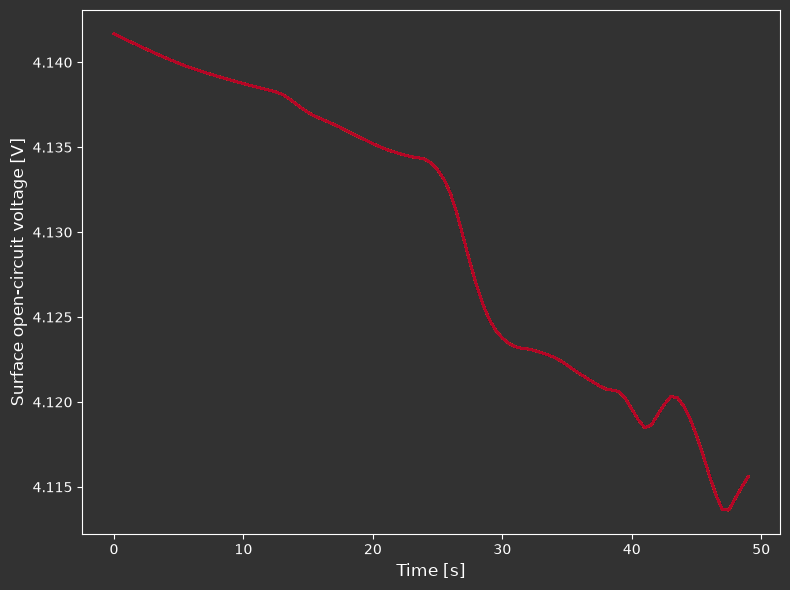

In [36]:
lp.plot_cells(output_d)
lp.show_plots()

The mean current is:

In [ ]:
I_mean = np.around(np.mean(drive_cycle[:, 1]), 3)
I_mean

Let's see what the simulation looks like when we just discharge at the mean current for 600 s.

In [ ]:
experiment = pybamm.Experiment(
    [f"Discharge at {I_mean} A for 90 s"], period="0.5 second"
)

In [ ]:
# Solve pack
output_m = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=experiment,
    initial_soc=0.75,
)

In [ ]:
lp.plot_pack(output_m)
plt.show()

In [ ]:
lp.compare_solution_output(output_d, output_m)
plt.show()

Let's see what happens when we change the period to 10 seconds

In [ ]:
experiment = pybamm.Experiment(
    [pybamm.step.current(drive_cycle)],
    period="10 seconds",
)

In [ ]:
# Solve pack
output_t = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=experiment,
    initial_soc=1.00,
)

In [ ]:
lp.plot_output(output_t)
plt.show()

The drive cycle units in time are modified by the experiment period